# Sephora Skincare: Where Is Customer Dissatisfaction Concentrated?
**Author:** Rhiana Le · **Data:** Sephora Products & Skincare Reviews (Kaggle, scraped Mar 2023)

**Scenario.** I am an analyst on Sephora's skincare merchandising team. Leadership wants to know which parts of the assortment are leaking customer satisfaction, so they can prioritize assortment reviews, vendor conversations, and product-page fixes.

**Notebook 01 covers:** data profiling → cleaning → Q1 (*Do star ratings and "would recommend" tell different stories?*) → why some categories underperform

In [10]:
import pandas as pd, numpy as np, glob, matplotlib.pyplot as plt
DATA_DIR = 'archive/'   # folder containing product_info.csv and reviews_*.csv
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 50)

## 1. Load and profile

In [11]:
products = pd.read_csv(DATA_DIR + 'product_info.csv')
cols = ['author_id','rating','is_recommended','helpfulness','total_feedback_count','submission_time',
        'review_text','review_title','skin_tone','skin_type','product_id','price_usd']
reviews = pd.concat([pd.read_csv(f, usecols=cols, dtype={'author_id': str})
                     for f in sorted(glob.glob(DATA_DIR + 'reviews_*.csv'))], ignore_index=True)
print('products:', products.shape, '| reviews:', reviews.shape)
print('Product categories:'); print(products.primary_category.value_counts().to_string())

products: (8494, 27) | reviews: (1094411, 12)
Product categories:
primary_category
Skincare           2420
Makeup             2369
Hair               1464
Fragrance          1432
Bath & Body         405
Mini Size           288
Men                  60
Tools & Brushes      52
Gifts                 4


In [12]:
(reviews.isna().mean()*100).round(1).sort_values(ascending=False).to_frame('% missing')

,% missing
helpfulness,51.3
review_title,28.4
skin_tone,15.6
is_recommended,15.3
skin_type,10.2
review_text,0.1
author_id,0.0
rating,0.0
total_feedback_count,0.0
submission_time,0.0


**Observations**
- The product table covers all of Sephora (8,494 products), but **reviews exist only for Skincare**. Scope of this project = skincare.
- `is_recommended` is missing for ~15% of reviews (customer skipped the question); `helpfulness` for ~51% (no votes yet). Neither blocks the analysis; we drop missing values only where a metric needs them.

## 2. Clean: one real customer review = one row

In [13]:
reviews['submission_time'] = pd.to_datetime(reviews.submission_time)
df = reviews.merge(products[['product_id','product_name','brand_name','secondary_category','price_usd']]
                   .rename(columns={'price_usd':'prod_price'}), on='product_id', how='left', validate='many_to_one')
key = ['author_id','review_text','submission_time','rating']
shared = df.duplicated(key, keep=False)
print(f'Reviews that appear on more than one product: {shared.sum():,} ({shared.mean():.1%})')
df[shared].groupby(key).product_name.apply(lambda s: ' | '.join(sorted(set(s)))).value_counts().head(5)

Reviews that appear on more than one product: 241,976 (22.1%)


product_name
Green Clean Makeup Meltaway Cleansing Balm Limited Edition Jumbo | Green Clean Makeup Removing Cleansing Balm           6135
Mini Superfood Antioxidant Cleanser | Superfood Antioxidant Cleanser                                                    5836
Cicapair Tiger Grass Color Correcting Treatment SPF 30 | Mini Cicapair Tiger Grass Color Correcting Treatment SPF 30    5022
Daily Microfoliant Exfoliator | Mini Daily Microfoliant Exfoliator                                                      4596
Jet Lag Mask | Mini Jet Lag Mask                                                                                        4414
Name: count, dtype: int64

**Data-quality finding.** About 22% of reviews are **syndicated**: Sephora shows the same review on the mini, jumbo, and full-size versions of a product. Counting them separately would double-count those customers and inflate popular products. I keep one copy of each review (product-level stats below use the first listing).

In [14]:
df = df.drop_duplicates(key).copy()
df['detractor'] = (df.rating <= 2).astype(int)
df.to_parquet('reviews_clean.parquet')   # reused by notebook 02
print(f'Distinct reviews: {len(df):,} | products: {df.product_id.nunique():,} | '
      f'{df.submission_time.min():%Y-%m} to {df.submission_time.max():%Y-%m}')

Distinct reviews: 971,390 | products: 2,266 | 2008-08 to 2023-03


## 3. Q1: Do star ratings and "would recommend" tell different stories?
Hypothesis: some products earn decent stars but customers still would not recommend them (hidden dissatisfaction).

In [15]:
k = df.dropna(subset=['is_recommended'])
p_rec = k.groupby('rating').is_recommended.mean()
p_rec.to_frame('P(recommend | stars)').round(3)

,P(recommend | stars)
rating,
1,0.008
2,0.037
3,0.360
4,0.967
5,0.999


Recommendation is almost a deterministic function of stars: 4–5 stars ≈ always recommend, 1–2 stars ≈ never. **Only 3-star reviews are genuinely split (~36% recommend).**

To test the hypothesis at product level, I compare each product's **actual** recommend rate with the rate **expected** from its star mix. A large negative gap would mean customers recommend it less than its stars suggest.

In [16]:
k = k.assign(expected=k.rating.map(p_rec))
g = (k.groupby(['product_id','product_name','brand_name','secondary_category'])
       .agg(n=('rating','size'), avg_star=('rating','mean'), rec=('is_recommended','mean'), exp=('expected','mean'))
       .reset_index().query('n >= 100'))
g['gap_pp'] = (g.rec - g.exp)*100
g['z'] = (g.rec - g.exp) / np.sqrt(g.exp*(1-g.exp)/g.n)
print(f'Products with >=100 reviews: {len(g):,}')
print(f'Correlation(avg stars, recommend rate): {g.avg_star.corr(g.rec):.3f}')
print(f'Gap (pp): mean {g.gap_pp.mean():.2f}, std {g.gap_pp.std():.2f}; |z|>3: {(g.z.abs()>3).sum()} products')

Products with >=100 reviews: 1,243
Correlation(avg stars, recommend rate): 0.972
Gap (pp): mean 0.02, std 1.24; |z|>3: 5 products


**Result: hypothesis rejected.** Stars and recommendations are near-perfectly correlated, and almost no product shows a statistically meaningful gap.

**So what?** This is a useful finding, not a dead end:
1. The team does **not** need two satisfaction KPIs. One is enough, and the most actionable version is the **detractor rate** (share of 1–2 star reviews). It is what "would not recommend" means in practice.
2. Average stars hide the tail: a 4.3-star average is compatible with very different shares of unhappy customers. Detractor rate measures that tail directly.

## 4. Where are detractors concentrated?

In [17]:
cat = df.groupby('secondary_category').detractor.agg(rate='mean', reviews='size').query('reviews > 3000')
cat['ci95'] = 1.96*np.sqrt(cat.rate*(1-cat.rate)/cat.reviews)
overall = df.detractor.mean()
cat = cat.sort_values('rate')
(cat.assign(rate_pct=cat.rate*100, ci95_pp=cat.ci95*100)[['rate_pct','ci95_pp','reviews']]
    .sort_values('rate_pct', ascending=False).round(2))

,rate_pct,ci95_pp,reviews
secondary_category,,,
Self Tanners,16.05,0.66,11934
High Tech Tools,14.60,0.91,5815
Sunscreen,13.60,0.34,39137
Wellness,12.77,0.65,10091
Eye Care,11.73,0.23,74852
Mini Size,10.96,0.55,12544
Value & Gift Sets,10.71,0.57,11175
Lip Balms & Treatments,10.70,0.24,61587
Treatments,10.08,0.13,216920


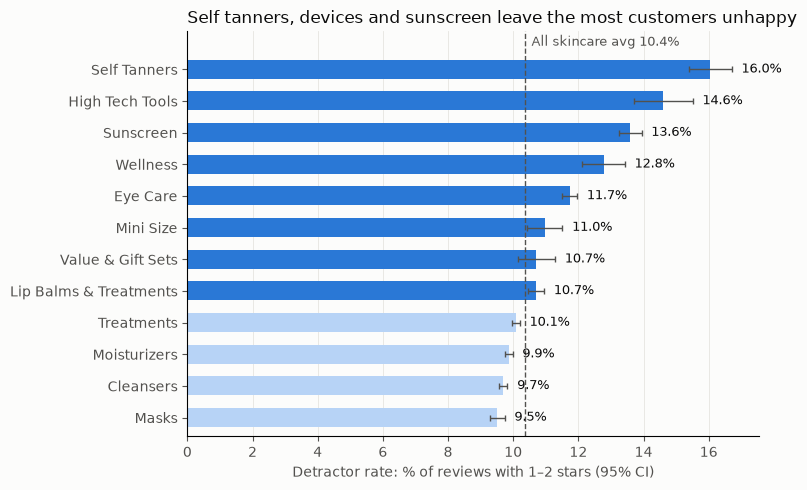

In [18]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor='#fcfcfb'); ax.set_facecolor('#fcfcfb')
above = cat.rate > overall
ax.barh(cat.index, cat.rate*100, xerr=cat.ci95*100, height=0.6,
        color=np.where(above, '#2a78d6', '#b7d3f6'), error_kw=dict(ecolor='#52514e', lw=1, capsize=2))
ax.axvline(overall*100, color='#52514e', ls='--', lw=1)
ax.text(overall*100+0.2, len(cat)-0.35, f'All skincare avg {overall:.1%}', color='#52514e', fontsize=9, va='bottom')
ax.set_ylim(-0.6, len(cat)+0.2)
for y,(v,c) in enumerate(zip(cat.rate*100, cat.ci95*100)):
    ax.text(v+c+0.3, y,  f'{v:.1f}%', va='center', fontsize=9, color='#0b0b0b')
ax.set_xlabel('Detractor rate: % of reviews with 1–2 stars (95% CI)', color='#52514e')
ax.set_title('Self tanners, devices and sunscreen leave the most customers unhappy', loc='left', fontsize=12, color='#0b0b0b')
for s in ['top','right']: ax.spines[s].set_visible(False)
ax.tick_params(colors='#52514e'); ax.grid(axis='x', color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('fig_q1_detractor_by_category.png', dpi=200); plt.show()

## 5. Why are these categories different? Testing my hypotheses
From my experience in beauty marketing, I expected these categories to suffer from an **expectation gap**: results are visible immediately and depend on the customer's own skin.

**H1: Self-tanner results depend on starting skin tone.** If true, lighter-skinned customers (where an orange or streaky result is most visible) should be unhappier than they are with ordinary products.

In [19]:
def det_by_tone(d, min_n):
    t = d.groupby('skin_tone').detractor.agg(rate='mean', n='size').query('n >= @min_n')
    return (t.rate*100).round(1)
tones = ['fairLight','fair','light','lightMedium','mediumTan','medium']
pd.DataFrame({'Self Tanners': det_by_tone(df[df.secondary_category=='Self Tanners'], 200),
              'Moisturizers + Cleansers (baseline)': det_by_tone(df[df.secondary_category.isin(['Moisturizers','Cleansers'])], 2000)}
            ).reindex(tones)

,Self Tanners,Moisturizers + Cleansers (baseline)
skin_tone,,
fairLight,18.8,10.9
fair,17.2,10.4
light,16.7,9.6
lightMedium,15.4,9.4
mediumTan,15.9,9.9
medium,12.3,9.3


**H1 supported.** For ordinary products, skin tone barely matters (~1–2 pp spread). For self tanners the spread grows to ~6.5 pp: fair-light customers have 18.8% detractors vs 12.3% for medium skin.

**H2: Customers complain about different things in each category

In [20]:
themes = {
 'Self Tanners':   {'orange / wrong color': r'orange|too dark|too light|not dark|colou?r', 'streaky / patchy': r'streak|patch|blotch|uneven',
                    'smell': r'smell|scent|odou?r', 'no result': r"nothing|no colou?r|didn.t (?:do|work)|barely"},
 'Sunscreen':      {'greasy / sticky': r'greas|oily|shiny|sticky', 'white cast': r'white ?cast|ashy|gr[ae]y',
                    'stings eyes': r'sting|burn|eye', 'pilling': r'pill', 'breakouts': r'break ?out|acne|pimple|clog'},
 'High Tech Tools':{'price / value': r'price|expensive|money|refund|return', 'broke / stopped working': r'broke|stopped working|died|defect|malfunction|charg|battery',
                    'no result': r"no (?:difference|result)|nothing|didn.t (?:do|work)|waste"}}
rows = []
for cat_name, pats in themes.items():
    txt = df[(df.secondary_category==cat_name) & (df.detractor==1)].review_text.fillna('').str.lower()
    for theme, pat in pats.items():
        rows.append({'category': cat_name, 'theme': theme, '% of detractor reviews': round(txt.str.contains(pat).mean()*100, 1), 'n detractors': len(txt)})
pd.DataFrame(rows).set_index(['category','theme'])

% of detractor reviews  n detractors
category        theme                                                        
Self Tanners    orange / wrong color                       53.3          1915
                streaky / patchy                           33.9          1915
                smell                                      26.6          1915
                no result                                  14.2          1915
Sunscreen       greasy / sticky                            35.3          5322
                white cast                                 15.4          5322
                stings eyes                                14.7          5322
                pilling                                    14.0          5322
                breakouts                                  12.7          5322
High Tech Tools price / value                              43.8           849
                broke / stopped working                    28.7           849
                no result                                  22.7           849

## Q1 takeaways
- **One KPI, not two.** "Would recommend" adds almost no information beyond stars (r ≈ 0.97). Track **detractor rate** as the satisfaction KPI.
- **Dissatisfaction is concentrated.** Self Tanners (~16%), High Tech Tools (~15%) and Sunscreen (~14%) have roughly 40–70% more detractors than core categories (~10%).
- **The causes differ, so the fixes differ:**

| Problem type | Evidence | Owner / fix |
|---|---|---|
| **Fit**: right product, wrong customer | Tanners: color complaints, worst for fair skin | Product page: shade guidance, skin-tone filters, "best for" tags |
| **Product**: the formula itself disappoints | Sunscreen: greasy, white cast, stinging | Vendor conversations, assortment review |
| **Value**: high price, low payoff | Devices: price/value, breakage | Pricing, warranty/returns, clearer claims |

- **What this data can't tell us:** whether sunscreen fails in hot or humid climates. Reviews have no location, so testing that would need regional data.
